<a href="https://colab.research.google.com/github/jmora420-hue/Ciencia_de_datos/blob/main/Continuaci%C3%B3n_An%C3%A1lisis_Lol.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [4]:
"""import requests
import pandas as pd
import time

API_KEY = "RGAPI-b32d78fb-49bd-4d34-a4b6-1611440975d1"
headers = {"X-Riot-Token": API_KEY}

def safe_request(url, headers):
    while True:
        res = requests.get(url, headers=headers)
        if res.status_code == 429:
            retry_after = int(res.headers.get("Retry-After", 5))
            print(f"   [Pausa API] Esperando {retry_after} segs...")
            time.sleep(retry_after + 1)
        else:
            return res

def historial_aatrox_top(game_name, tag_line, region_routing="americas", target_count=10):
    print(f"Buscando las últimas {target_count} partidas de {game_name}#{tag_line} con Aatrox en TOP...")

    # 1. Obtener PUUID
    url_account = f"https://{region_routing}.api.riotgames.com/riot/account/v1/accounts/by-riot-id/{game_name}/{tag_line}"
    res_account = safe_request(url_account, headers)

    if res_account.status_code != 200:
        print("Error al encontrar al jugador.")
        return pd.DataFrame()

    puuid = res_account.json()["puuid"]
    partidas_data = []
    start_index = 0
    batch_size = 50

    while len(partidas_data) < target_count:
        url_match_ids = f"https://{region_routing}.api.riotgames.com/lol/match/v5/matches/by-puuid/{puuid}/ids?start={start_index}&count={batch_size}"
        match_ids = safe_request(url_match_ids, headers).json()

        if not match_ids:
            break # Se acabó el historial

        for match_id in match_ids:
            if len(partidas_data) >= target_count:
                break

            url_match = f"https://{region_routing}.api.riotgames.com/lol/match/v5/matches/{match_id}"
            res_match = safe_request(url_match, headers)

            if res_match.status_code == 200:
                info = res_match.json()["info"]

                for p in info["participants"]:
                    # FILTRO: Jugador correcto + Aatrox + TOP
                    if p["puuid"] == puuid and p["championName"] == "Aatrox" and p.get("teamPosition") == "TOP":

                        # Extraer la sección de "Challenges" (estadísticas avanzadas)
                        retos = p.get("challenges", {})

                        # Cálculos básicos
                        minutos = info["gameDuration"] / 60
                        deaths = max(1, p["deaths"]) # Evitar división por cero
                        kda_ratio = round((p["kills"] + p["assists"]) / deaths, 2)
                        cs_total = p["totalMinionsKilled"] + p["neutralMinionsKilled"]

                        # Objetos (IDs omitiendo los espacios vacíos que son 0)
                        items = [p[f"item{i}"] for i in range(6) if p[f"item{i}"] != 0]

                        # Runa Principal (Keystone) - Viene anidada en el JSON
                        try:
                            runa_principal = p["perks"]["styles"][0]["selections"][0]["perk"]
                        except:
                            runa_principal = "Desconocida"

                        # Construir la fila del Dataset
                        partidas_data.append({
                            "Resultado": "Victoria" if p["win"] else "Derrota",
                            "Minutos": round(minutos, 1),
                            "KDA": f"{p['kills']}/{p['deaths']}/{p['assists']}",
                            "Ratio KDA": kda_ratio,
                            "KP %": f"{round(retos.get('killParticipation', 0) * 100, 1)}%",
                            "Solo Kills": retos.get("soloKills", 0),
                            "Placas": retos.get("turretPlatesTaken", 0),
                            "CS / Min": round(cs_total / minutos, 1),
                            "Oro / Min": round(retos.get("goldPerMinute", 0), 1),
                            "Daño / Min": round(retos.get("damagePerMinute", 0), 1),
                            "Daño a Objetivos": p["damageDealtToObjectives"],
                            "Daño Recibido": p["totalDamageTaken"],
                            "Curación Total": p["totalHeal"],
                            "IDs Objetos": items,
                            "ID Runa": runa_principal
                        })
                        print(f" -> Partida {len(partidas_data)} encontrada!")
                        break
            time.sleep(0.05)
        start_index += batch_size

    return pd.DataFrame(partidas_data)

# ==========================================
# EJECUCIÓN
# ==========================================
df_aatrox_analisis = historial_aatrox_top("Rabbids3000", "LAN", target_count=10)

print("\n--- DATASET: Análisis de Aatrox TOP (10 Partidas) ---")
display(df_aatrox_analisis)

Buscando las últimas 10 partidas de Rabbids3000#LAN con Aatrox en TOP...
 -> Partida 1 encontrada!
 -> Partida 2 encontrada!
 -> Partida 3 encontrada!
 -> Partida 4 encontrada!
 -> Partida 5 encontrada!
 -> Partida 6 encontrada!
 -> Partida 7 encontrada!
 -> Partida 8 encontrada!
 -> Partida 9 encontrada!
 -> Partida 10 encontrada!

--- DATASET: Análisis de Aatrox TOP (10 Partidas) ---


,Resultado,Minutos,KDA,Ratio KDA,KP %,Solo Kills,Placas,CS / Min,Oro / Min,Daño / Min,Daño a Objetivos,Daño Recibido,Curación Total,IDs Objetos,ID Runa
0,Derrota,31.8,12/4/5,4.25,73.9%,4,17,7.1,519.3,1045.0,12496,34539,17865,"[2517, 6697, 6333, 3047, 3033, 3133]",8010
1,Derrota,27.4,11/5/3,2.80,73.7%,4,7,7.4,507.3,1119.6,6262,28898,13282,"[1037, 6697, 3047, 6333, 2517, 2021]",8010
2,Derrota,33.3,16/7/2,2.57,50.0%,9,7,5.8,488.4,1235.2,10873,48291,22291,"[2517, 3111, 6697, 3161, 6333, 3155]",8010
3,Derrota,36.7,8/8/4,1.50,41.4%,4,11,5.8,401.8,1322.0,24438,51206,22394,"[6333, 6692, 3047, 3161, 3156]",8010
4,Victoria,26.9,10/4/9,4.75,54.3%,8,14,7.3,488.7,1197.4,14741,28970,15195,"[1037, 6697, 3047, 6692, 3161, 3133]",8010
5,Victoria,40.4,20/6/6,4.33,52.0%,5,10,5.9,489.4,1828.1,12395,71597,40234,"[2517, 6697, 3047, 3161, 6333, 3156]",8010
6,Derrota,38.3,18/10/4,2.20,57.9%,11,17,6.4,501.1,1295.8,21383,64747,26785,"[3156, 6697, 3047, 3161, 6333, 3033]",8010
7,Victoria,26.9,26/1/5,31.00,75.6%,15,15,7.2,651.2,1901.0,22691,31299,24909,"[1055, 3161, 3047, 6333, 6694, 2517]",8010
8,Derrota,29.4,2/7/5,1.00,28.0%,1,4,6.4,326.7,1053.7,4148,37968,15812,"[1055, 6692, 3047, 3161, 3035, 1036]",8010
9,Derrota,34.6,5/8/4,1.12,32.1%,4,6,6.5,353.8,774.8,10515,40668,13470,"[1055, 6695, 3047, 3033, 3161, 3155]",8010


In [5]:
"""from google.colab import files

# Guardar como CSV (index=False evita que se guarde una columna inútil de números 0, 1, 2...)
df_aatrox_analisis.to_csv('rabbids_aatrox2.0.csv', index=False)

# Forzar la descarga al navegador
files.download('rabbids_aatrox2.0.csv')


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [1]:
!pip install statsmodels
!pip install wquantiles

In [3]:
import pandas as pd
import numpy as np
from scipy.stats import trim_mean
from statsmodels import robust
import wquantiles
import seaborn as sns
import matplotlib.pyplot as plt
df_rabbids=pd.read_csv('/content/drive/MyDrive/Colab Notebooks/Ciencia de datos/rabbids_aatrox2.0.csv')
df_rabbids.head(10)

,Resultado,Minutos,KDA,Ratio KDA,KP %,Solo Kills,Placas,CS / Min,Oro / Min,Daño / Min,Daño a Objetivos,Daño Recibido,Curación Total,IDs Objetos,ID Runa
0,Derrota,31.8,12/4/5,4.25,73.9%,4,17,7.1,519.3,1045.0,12496,34539,17865,"[2517, 6697, 6333, 3047, 3033, 3133]",8010
1,Derrota,27.4,11/5/3,2.80,73.7%,4,7,7.4,507.3,1119.6,6262,28898,13282,"[1037, 6697, 3047, 6333, 2517, 2021]",8010
2,Derrota,33.3,16/7/2,2.57,50.0%,9,7,5.8,488.4,1235.2,10873,48291,22291,"[2517, 3111, 6697, 3161, 6333, 3155]",8010
3,Derrota,36.7,8/8/4,1.50,41.4%,4,11,5.8,401.8,1322.0,24438,51206,22394,"[6333, 6692, 3047, 3161, 3156]",8010
4,Victoria,26.9,10/4/9,4.75,54.3%,8,14,7.3,488.7,1197.4,14741,28970,15195,"[1037, 6697, 3047, 6692, 3161, 3133]",8010
5,Victoria,40.4,20/6/6,4.33,52.0%,5,10,5.9,489.4,1828.1,12395,71597,40234,"[2517, 6697, 3047, 3161, 6333, 3156]",8010
6,Derrota,38.3,18/10/4,2.20,57.9%,11,17,6.4,501.1,1295.8,21383,64747,26785,"[3156, 6697, 3047, 3161, 6333, 3033]",8010
7,Victoria,26.9,26/1/5,31.00,75.6%,15,15,7.2,651.2,1901.0,22691,31299,24909,"[1055, 3161, 3047, 6333, 6694, 2517]",8010
8,Derrota,29.4,2/7/5,1.00,28.0%,1,4,6.4,326.7,1053.7,4148,37968,15812,"[1055, 6692, 3047, 3161, 3035, 1036]",8010
9,Derrota,34.6,5/8/4,1.12,32.1%,4,6,6.5,353.8,774.8,10515,40668,13470,"[1055, 6695, 3047, 3033, 3161, 3155]",8010


In [4]:
#Reemplazamos Victorias por un 1 y derrotas por un 0, para manejarlos como un bit binario
df_rabbids['Resultado'] = df_rabbids['Resultado'].replace({'Victoria': 1, 'Derrota': 0})

#Dividir la columna 'KDA' en 'Kills', 'Deaths' y 'Assists'
df_rabbids[['Kills', 'Deaths', 'Assists']] = df_rabbids['KDA'].str.split('/', expand=True).astype(float)

df_rabbids.sample(10)

/tmp/ipykernel_3859/2470347622.py:2: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df_rabbids['Resultado'] = df_rabbids['Resultado'].replace({'Victoria': 1, 'Derrota': 0})


,Resultado,Minutos,KDA,Ratio KDA,KP %,Solo Kills,Placas,CS / Min,Oro / Min,Daño / Min,Daño a Objetivos,Daño Recibido,Curación Total,IDs Objetos,ID Runa
3,0,36.7,8/8/4,1.50,41.4%,4,11,5.8,401.8,1322.0,24438,51206,22394,"[6333, 6692, 3047, 3161, 3156]",8010
4,1,26.9,10/4/9,4.75,54.3%,8,14,7.3,488.7,1197.4,14741,28970,15195,"[1037, 6697, 3047, 6692, 3161, 3133]",8010
1,0,27.4,11/5/3,2.80,73.7%,4,7,7.4,507.3,1119.6,6262,28898,13282,"[1037, 6697, 3047, 6333, 2517, 2021]",8010
5,1,40.4,20/6/6,4.33,52.0%,5,10,5.9,489.4,1828.1,12395,71597,40234,"[2517, 6697, 3047, 3161, 6333, 3156]",8010
0,0,31.8,12/4/5,4.25,73.9%,4,17,7.1,519.3,1045.0,12496,34539,17865,"[2517, 6697, 6333, 3047, 3033, 3133]",8010
9,0,34.6,5/8/4,1.12,32.1%,4,6,6.5,353.8,774.8,10515,40668,13470,"[1055, 6695, 3047, 3033, 3161, 3155]",8010
2,0,33.3,16/7/2,2.57,50.0%,9,7,5.8,488.4,1235.2,10873,48291,22291,"[2517, 3111, 6697, 3161, 6333, 3155]",8010
8,0,29.4,2/7/5,1.00,28.0%,1,4,6.4,326.7,1053.7,4148,37968,15812,"[1055, 6692, 3047, 3161, 3035, 1036]",8010
6,0,38.3,18/10/4,2.20,57.9%,11,17,6.4,501.1,1295.8,21383,64747,26785,"[3156, 6697, 3047, 3161, 6333, 3033]",8010
7,1,26.9,26/1/5,31.00,75.6%,15,15,7.2,651.2,1901.0,22691,31299,24909,"[1055, 3161, 3047, 6333, 6694, 2517]",8010


In [5]:
#Definir manualmente el vector de columnas a analizar (excluyendo Resultado, ID Runa e IDs Objetos)
cols_analizar = [
    'Minutos', 'Ratio KDA', 'Solo Kills', 'Placas',
    'CS / Min', 'Oro / Min', 'Daño / Min', 'Daño a Objetivos',
    'Daño Recibido', 'Curación Total', 'Kills', 'Deaths', 'Assists'
]

#Calcular medidas de tendencia central
print("=== MEDIDAS DE TENDENCIA CENTRAL (Rabbids3000) ===")
print("\n--- Media ---")
print(df_rabbids[cols_analizar].mean())

print("\n--- Mediana ---")
print(df_rabbids[cols_analizar].median())

print("\n--- Moda ---")
print(df_rabbids[cols_analizar].mode().iloc[0])

=== MEDIDAS DE TENDENCIA CENTRAL (Rabbids3000) ===

--- Media ---
Minutos                32.570
Ratio KDA               5.552
Solo Kills              6.500
Placas                 10.800
CS / Min                6.580
Oro / Min             472.770
Daño / Min           1277.260
Daño a Objetivos    13994.200
Daño Recibido       43818.300
Curación Total      21223.700
Kills                  12.800
Deaths                  6.000
Assists                 4.700
dtype: float64

--- Mediana ---
Minutos                32.550
Ratio KDA               2.685
Solo Kills              4.500
Placas                 10.500
CS / Min                6.450
Oro / Min             489.050
Daño / Min           1216.300
Daño a Objetivos    12445.500
Daño Recibido       39318.000
Curación Total      20078.000
Kills                  11.500
Deaths                  6.500
Assists                 4.500
dtype: float64

--- Moda ---
Minutos                26.9
Ratio KDA               1.0
Solo Kills              4.0
Placas   

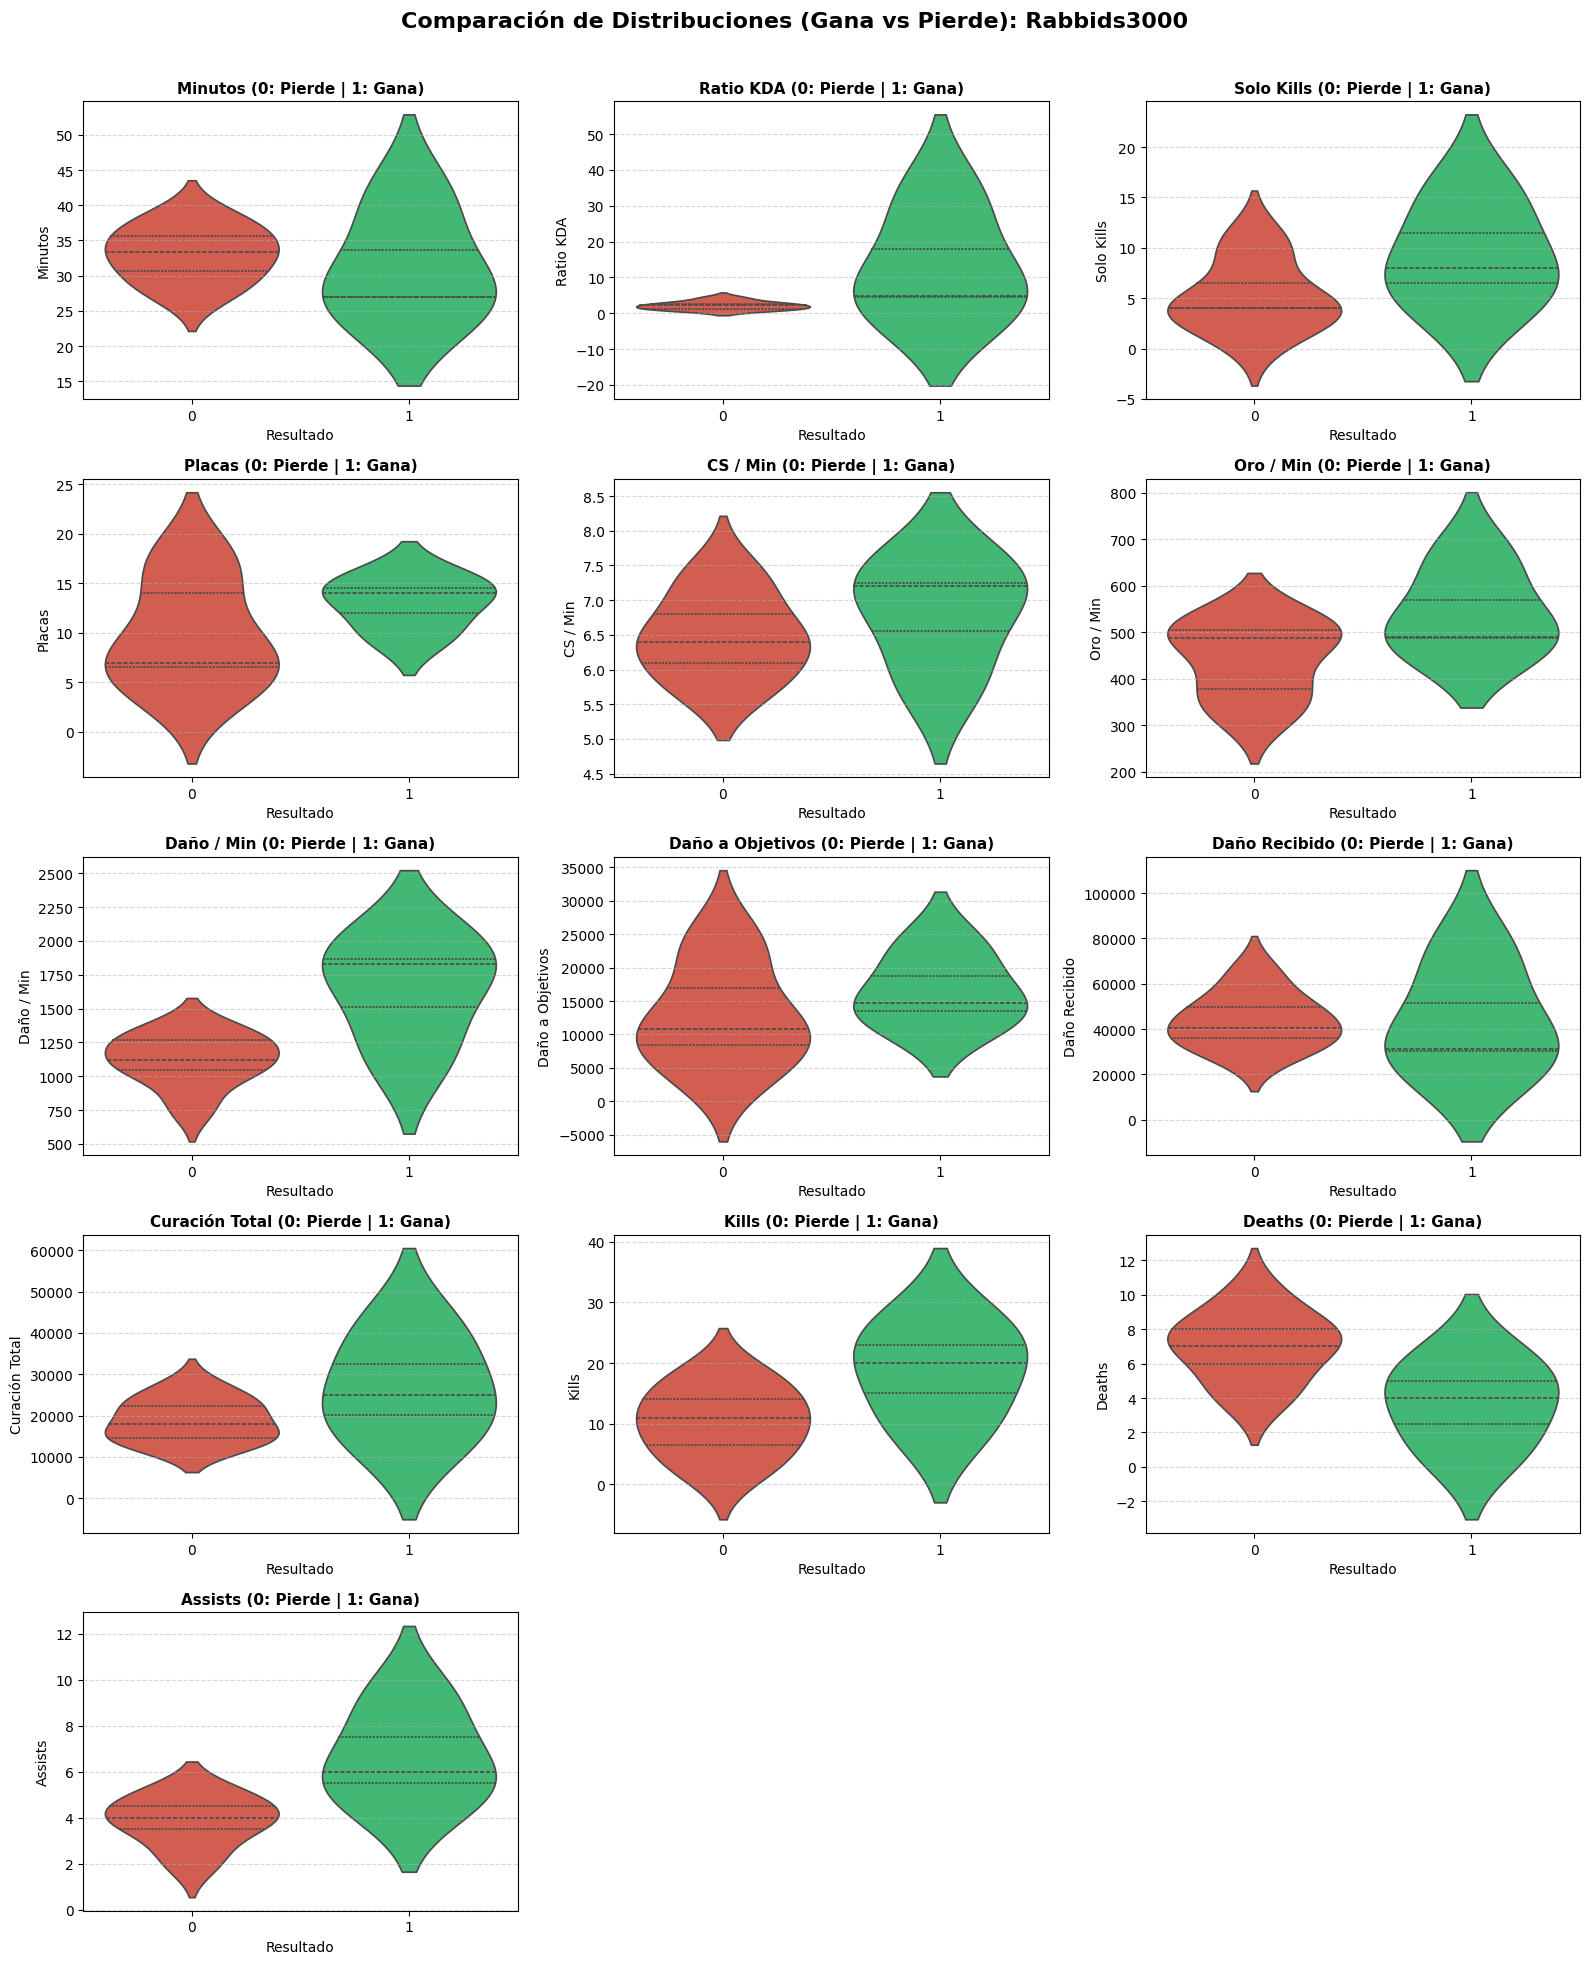

In [11]:
# COMPARACIÓN DE DISTRIBUCIONES: VICTORIAS VS DERROTAS DE RABBIDS3000
fig, axes = plt.subplots(5, 3, figsize=(16, 20))
fig.suptitle('Comparación de Distribuciones (Gana vs Pierde): Rabbids3000', fontsize=16, fontweight='bold')

axes_flat = axes.flatten()

for i, col in enumerate(cols_analizar):
    ax = axes_flat[i]

    sns.violinplot(
        x='Resultado',
        y=col,
        hue='Resultado',
        data=df_rabbids,
        ax=ax,
        palette=['#e74c3c', '#2ecc71'],  # Rojo para Derrota (0), Verde para Victoria (1)
        legend=False,
        inner='quartile'
    )

    ax.set_title(f'{col} (0: Pierde | 1: Gana)', fontweight='bold', fontsize=11)
    ax.set_xlabel('Resultado')
    ax.set_ylabel(col)
    ax.grid(axis='y', linestyle='--', alpha=0.5)

# Ocultar los subgráficos que sobren de la cuadrícula
for j in range(len(cols_analizar), len(axes_flat)):
    fig.delaxes(axes_flat[j])

plt.tight_layout(rect=[0, 0, 1, 0.97])
plt.show()

In [12]:
import ast

print(type(df_rabbids["IDs Objetos"][0]))

if isinstance(df_rabbids["IDs Objetos"][0], str):
  df_rabbids["IDs Objetos"]=df_rabbids["IDs Objetos"].apply(ast.literal_eval)

df_rabbids["IDs Objetos"].head()

<class 'str'>


,IDs Objetos
0,"[2517, 6697, 6333, 3047, 3033, 3133]"
1,"[1037, 6697, 3047, 6333, 2517, 2021]"
2,"[2517, 3111, 6697, 3161, 6333, 3155]"
3,"[6333, 6692, 3047, 3161, 3156]"
4,"[1037, 6697, 3047, 6692, 3161, 3133]"


In [13]:
import requests

# Versión más reciente del juego
version=requests.get("https://ddragon.leagueoflegends.com/api/versions.json").json()[0]

# Catálogo de objetos en español
url="https://ddragon.leagueoflegends.com/cdn/"+version+"/data/es_MX/item.json"
items=requests.get(url).json()["data"]

print("Versión:", version)
print("Objetos en el catálogo:", len(items))

Versión: 16.22.1
Objetos en el catálogo: 863


In [14]:
import re

nombres={}
descripcion_limpia={}
stats={}

for id_item in items:
  numero=int(id_item)
  texto=items[id_item]["description"]

  nombres[numero]=items[id_item]["name"]
  descripcion_limpia[numero]=re.sub("<.*?>"," ",texto).strip()

  # Solo la parte de atributos (antes de la pasiva)
  if "</stats>" in texto:
    parte_stats=texto.split("</stats>")[0]
  else:
    parte_stats=""
  stats[numero]=re.sub("<.*?>"," ",parte_stats).strip()

print(nombres[3047])
print(stats[3047])

Punteras de Acero Revestidas
25  de Armadura  45  de Velocidad de Movimiento


In [15]:
objetos=df_rabbids["IDs Objetos"].explode()

for id_item in objetos.unique():
  print(id_item, "-", nombres.get(id_item,"NO ENCONTRADO"))
  print("   ", stats.get(id_item,""))

2517 - Hambre Infinita
    65  de Daño de Ataque  5%  de Omnivampirismo  20%  de Tenacidad
6697 - Arrogancia
    55  de Daño de Ataque  18  de Letalidad  10  de Aceleración de Habilidad
6333 - Danza de la Muerte
    60  de Daño de Ataque  50  de Armadura  15  de Aceleración de Habilidad
3047 - Punteras de Acero Revestidas
    25  de Armadura  45  de Velocidad de Movimiento
3033 - Recordatorio Mortal
    35  de Daño de Ataque  30%  de Penetración de Armadura  25%  de Probabilidad de Golpe Crítico
3133 - Martillo de Guerra de Caulfield
    20  de Daño de Ataque  10  de Aceleración de Habilidad
1037 - Picacha
    25  de Daño de Ataque
2021 - Excavador de Túneles
    15  de Daño de Ataque  250  de Vida
3111 - Botas de Mercurio
    20  de Resistencia Mágica  45  de Velocidad de Movimiento  30%  de Tenacidad
3161 - Lanza de Shojin
    45  de Daño de Ataque  450  de Vida
3155 - Sorbechizos
    25  de Daño de Ataque  25  de Resistencia Mágica
6692 - Eclipse
    60  de Daño de Ataque  15  de Ac

In [16]:
conteo_objetos=objetos.map(nombres).value_counts()
print("Total de partidas:", len(df_rabbids))
conteo_objetos

Total de partidas: 10


,count
IDs Objetos,
Punteras de Acero Revestidas,9
Lanza de Shojin,8
Danza de la Muerte,7
Arrogancia,6
Hambre Infinita,5
Recordatorio Mortal,3
Fauces de Malmortius,3
Espada de Doran,3
Eclipse,3


In [17]:
top=objetos.value_counts().head(10)

tabla=pd.DataFrame({
    "Objeto": top.index.map(nombres),
    "Veces": top.values,
    "% de partidas": (top.values/len(df_rabbids)*100).round(1)
})
display(tabla)

# Descripción de los 5 favoritos
for id_item in top.index[:5]:
  print(nombres.get(id_item), "->", descripcion_limpia.get(id_item))
  print()

,Objeto,Veces,% de partidas
0,Punteras de Acero Revestidas,9,90.0
1,Lanza de Shojin,8,80.0
2,Danza de la Muerte,7,70.0
3,Arrogancia,6,60.0
4,Hambre Infinita,5,50.0
5,Recordatorio Mortal,3,30.0
6,Fauces de Malmortius,3,30.0
7,Espada de Doran,3,30.0
8,Eclipse,3,30.0
9,Martillo de Guerra de Caulfield,2,20.0


Punteras de Acero Revestidas -> 25  de Armadura  45  de Velocidad de Movimiento    Revestimiento  Reduce el daño recibido de los ataques en un 10%.

Lanza de Shojin -> 45  de Daño de Ataque  450  de Vida    Fuerza del Dragón   Obtienes 25 de Aceleración de Habilidad para habilidades básicas.   Voluntad Enfocada   Al infligir daño con habilidades, el daño de las habilidades y de la pasiva de tu campeón aumenta en un 3% durante 6 seg. (Se acumula 4 veces).

Danza de la Muerte -> 60  de Daño de Ataque  50  de Armadura  15  de Aceleración de Habilidad    Ignorar Dolor  Un porcentaje del daño recibido se distribuye a lo largo de 3 seg.   Desafiar  Cuando un campeón muere en un lapso de 3 seg después de que le hayas infligido daño, se disipa el daño restante de  Ignorar Dolor  y recuperas  vida  a lo largo de 2 seg.

Arrogancia -> 55  de Daño de Ataque  18  de Letalidad  10  de Aceleración de Habilidad    Eminencia  Cuando un campeón al que le infligiste daño muere en 3 seg, obtienes  0 de D

In [18]:
atributos={
    "Daño de ataque": ["daño de ataque"],
    "Poder de habilidad": ["poder de habilidad"],
    "Armadura": ["armadura"],
    "Resistencia mágica": ["resistencia mágica"],
    "Vida": ["vida"],
    "Velocidad de ataque": ["velocidad de ataque"],
    "Celeridad de habilidad": ["celeridad de habilidad","aceleración de habilidad"],
    "Crítico": ["crítico"],
    "Penetración": ["penetración"],
    "Velocidad de movimiento": ["velocidad de movimiento"],
    "Curación / robo de vida": ["curación","robo de vida","vampirismo"]
}

conteo={}
for atributo in atributos:
  conteo[atributo]=0
  for id_item in objetos:
    texto=stats.get(id_item,"").lower()
    for palabra in atributos[atributo]:
      if palabra in texto:
        conteo[atributo]=conteo[atributo]+1
        break

resultado=pd.Series(conteo).sort_values(ascending=False)
print(resultado)
print()
print("En % de objetos comprados:")
print((resultado/len(objetos)*100).round(1))

Daño de ataque             49
Celeridad de habilidad     22
Armadura                   21
Vida                       12
Velocidad de movimiento    10
Curación / robo de vida     8
Resistencia mágica          6
Penetración                 5
Crítico                     3
Poder de habilidad          0
Velocidad de ataque         0
dtype: int64

En % de objetos comprados:
Daño de ataque             83.1
Celeridad de habilidad     37.3
Armadura                   35.6
Vida                       20.3
Velocidad de movimiento    16.9
Curación / robo de vida    13.6
Resistencia mágica         10.2
Penetración                 8.5
Crítico                     5.1
Poder de habilidad          0.0
Velocidad de ataque         0.0
dtype: float64


In [21]:
from sklearn.feature_extraction.text import CountVectorizer

descripciones_usadas=objetos.map(descripcion_limpia).fillna("")

palabras_vacias=["cuando","puede","hasta","durante","después","mientras","otros","segundos",
                 "contra","cada","sobre","entre","desde","estos","estas","luego","tras",
                 "campeón","obtienes","muere","recibido","largo","infligir","infligido",
                 "ignorar","habilidades","además","como","pero","solo","esto","esta","este",
                 "dado","esos","unos","tipo","cual","mismo","misma","hacia","según","nivel",
                 "aumenta","aumentas","ganas","pasiva","activa","único","unico"]

# Palabras de 4 letras o más (así entra "daño", "vida", "oro")
cv=CountVectorizer(max_features=15, token_pattern=r"\b\w{4,}\b", stop_words=palabras_vacias)
matriz=cv.fit_transform(descripciones_usadas)

df_vec=pd.DataFrame(matriz.toarray(), columns=cv.get_feature_names_out())
df_vec.sum().sort_values(ascending=False)

,0
daño,132
ataque,60
aceleración,35
habilidad,35
vida,25
armadura,21
omnivampirismo,16
dolor,14
ataques,12
reduce,11


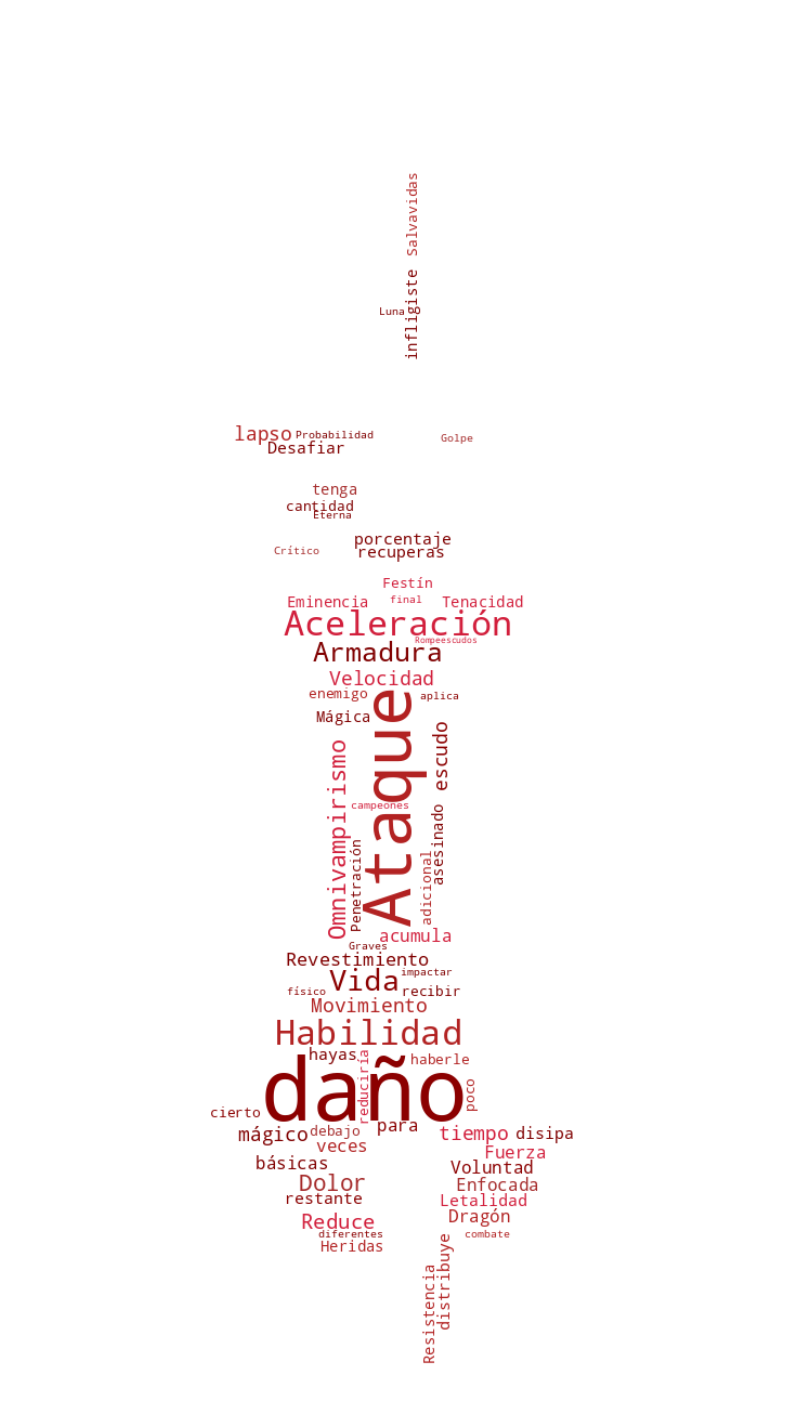

In [26]:
from wordcloud import WordCloud
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt
import random

# Texto: descripciones de los objetos que compra
texto_limpio = " ".join(descripciones_usadas)

# Máscara: pasamos la imagen a escala de grises
imagen = Image.open("/content/drive/MyDrive/Colab Notebooks/Espada.webp").convert("L")
mascara_gris = np.array(imagen)

# Ajustamos la máscara:
mascara = np.where(mascara_gris > 150, 255, 0)

# Función de color personalizada para garantizar tonos rojos oscuros de alto contraste
def color_rojo_oscuro(word, font_size, position, orientation, random_state=None, **kwargs):
    # Tonos: Rojo Oscuro, Carmesí, Marrón Rojizo, Rojo Sangre
    colores = ["#800000", "#8B0000", "#A52A2A", "#B22222", "#D21F3C"]
    return random.choice(colores)

nube = WordCloud(
    background_color="white",
    mask=mascara,
    color_func=color_rojo_oscuro, # Aplicamos los colores de alto contraste
    stopwords=set(palabras_vacias),
    min_word_length=4,
    min_font_size=8,              # Evita que las palabras sean exageradamente pequeñas
    max_font_size=80,             # Controla el tamaño máximo para mantener balance
    collocations=False,
    max_words=120,                # Reducimos ligeramente el tope para evitar saturación ilegible
    width=1000,
    height=1200,
    random_state=42
).generate(texto_limpio)

plt.figure(figsize=(10, 12), dpi=150) # Mayor tamaño y DPI para máxima nitidez
plt.imshow(nube, interpolation='bilinear')
plt.axis("off")
plt.show()

In [22]:
#Posición promedio de sus 10 objetos favoritos (1 = lo compra primero, 6 = lo compra último)
top=objetos.value_counts().head(10)

posicion_promedio={}
for id_item in top.index:
  lugares=[]
  for lista in df_rabbids["IDs Objetos"]:
    if id_item in lista:
      lugares.append(lista.index(id_item)+1)
  posicion_promedio[nombres[id_item]]=round(sum(lugares)/len(lugares),1)

pd.Series(posicion_promedio).sort_values()

,0
Espada de Doran,1.0
Arrogancia,2.2
Eclipse,2.7
Hambre Infinita,2.8
Punteras de Acero Revestidas,3.1
Danza de la Muerte,3.9
Fauces de Malmortius,4.0
Lanza de Shojin,4.0
Recordatorio Mortal,5.0
Martillo de Guerra de Caulfield,6.0


In [23]:
#Build típica
print("Build típica:")
for id_item in objetos.value_counts().head(6).index:
  print("-", nombres[id_item])

Build típica:
- Punteras de Acero Revestidas
- Lanza de Shojin
- Danza de la Muerte
- Arrogancia
- Hambre Infinita
- Recordatorio Mortal
